# AP 155 Lab Exercise
---
## Exercise 13: Ordinary differential equations

_Instructions_:
- **Report Figure:** Generate two figures: (1) famous Lorenz butterfly $x-z$ plot and (2) Van-der-Pol oscillator phase space plot
- **Report Discussion:** Explain the dynamics in the figures. Discuss how both Euler's method and Runge-Kutta method work in a nutshell. Distinguish the advantages and disadvantages between Euler vs RK4.
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Gonzales, Naeumi
- _Student No._: 2024-11022
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness  | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figure

![Lorenz strange attractor (z vs. x projection)](famous_Lorenz_butterfly_plot.png)

**Figure 1. Figure 1. Lorenz strange attractor (z vs. x projection).**
Trajectory of the Lorenz system for σ = 10, ρ = 28, β = 8/3, starting from (0, 1, 0) over 0 ≤ t ≤ 50. The path traces a butterfly-shaped pattern, looping around two centers without ever repeating or crossing itself in 3D.

![Van der Pol phase space](vanderpol.png)

**Figure 2. Van der Pol oscillator phase-space portrait.**
Velocity (dx/dt) versus position (x) for μ = 1, 2, and 4, starting from (1, 0) over 0 ≤ t ≤ 20. Each curve spirals out to a closed loop (the limit cycle), which becomes more stretched and distorted as μ increases. 

### Report discussion

**Explain the dynamics in the figures.**
Figure 1 shows chaos. The path loops around one wing of the butterfly a few times, then suddenly hops to the other wing, in a pattern that looks random even though the equations contain no randomness at all. It never repeats or crosses itself, yet it stays inside the same butterfly shape. That is why a tiny change in the starting point leads to a completely different future. Figure 2 shows a self-sustaining rhythm. Starting from the same point, each curve spirals into a closed loop called a limit cycle. Small swings get pushed bigger, and large swings get damped down, so the motion settles into one steady loop. A larger μ stretches that loop into a lopsided shape, with slow drifts followed by sudden, rapid swings.

**Discuss how both Euler's method and Runge-Kutta method work in a nutshell.**
Both methods predict where a system will be next by taking many tiny time steps, using a rule that says how fast things are changing at that moment. Euler's method is the simplest version: it checks the current slope and heads straight along it for one step, like walking in a straight line while only looking at the ground under your feet. Because the real path curves, each step drifts slightly off course. Runge-Kutta 4 (RK4) fixes this by checking the slope four times within each step, at the start, twice in the middle, and at the end, and then averaging them with extra weight on the middle readings. It is like glancing ahead before every stride, so each step follows the bend of the path instead of cutting across it.

**Distinguish the advantages and disadvantages between Euler vs RK4.**
Euler's method is very simple to write, easy to understand, and cheap to compute, since it needs just one slope evaluation per step. However, it is not very accurate, because errors build up quickly. In oscillating systems it tends to add energy, so waves slowly grow instead of staying steady, and good results require extremely small steps. RK4, on the other hand, is far more accurate for the same step size, so it can take larger steps and still track curved or oscillating motion well. It also stays stable much longer, which matters for delicate systems like the Lorenz attractor. Its drawbacks are that it does more work per step (four slope evaluations instead of one) and is slightly more complex to code. It can also struggle with very "stiff" problems, such as the sharp swings at large μ in van der Pol, unless the step size is kept small. In short, Euler trades accuracy for simplicity, while RK4 trades extra effort for far better results.

### Other comments
- none


---
## Section 2: Code

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import seaborn as sns # Guide: https://seaborn.pydata.org/tutorial/introduction.html
sns.set_theme(style="darkgrid")

rng = np.random.default_rng()

### Practice: Simple pendulum
$$\frac{d^2\theta}{dt^2}=-\frac{g}{l}\sin\theta $$

- Variables: ${\theta}$
- Parameters: ${g, l}$

To solve a second-order ODE, we reduce it to two first-order ODEs.
Let $\theta = y_0$ and $\omega = \frac{d\theta}{dt} = y_1$.
The system becomes:
\begin{align}
\frac{d \theta}{dt} &= \omega \\
\frac{d \omega}{dt} &= -\frac{g}{l}\sin(\theta)
\end{align}

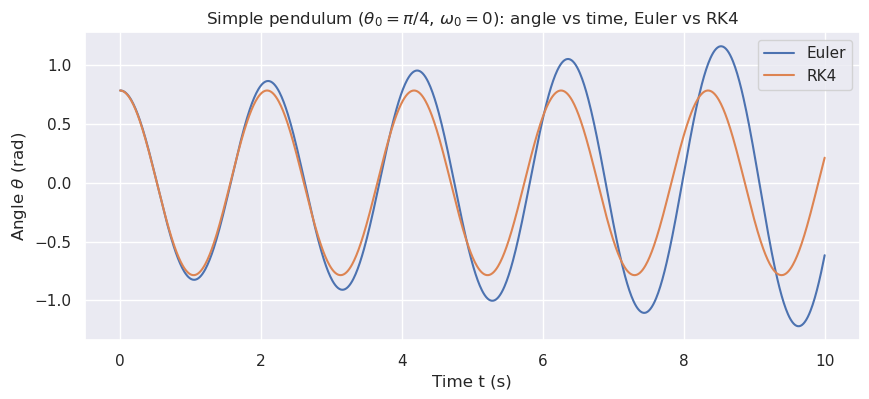

In [2]:
# practice mode

# global constants
g = 9.81    # gravitational acceleration (m/s^2)
l = 1.0     # pendulum length (m)

def pendulum_ode(t, R):
    # R is a vector containing the two variables theta, omega

    theta, omega = R                 # unpack R
    f0 = omega                       # dtheta/dt = omega
    f1 = -(g/l)*np.sin(theta)        # domega/dt = -(g/l) sin(theta)
    return np.array([f0, f1])


# given time interval from 0 to 10 seconds sampled at 1000 pts, define a, b, n
a, b, n = 0.0, 10.0, 1000

# init conds (arbitrary): pi/4 angle, 0 initial velocity
yinit = np.array([np.pi/4, 0.0]) # theta0, omega0

def eulergen(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit)))
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        y += h*f(x, y)
    return xs, ys


def rk4gen(fs,a,b,n,yinits):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j,x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals)
        k1 = h*fs(x+h/2, yvals+k0/2)
        k2 = h*fs(x+h/2, yvals+k1/2)
        k3 = h*fs(x+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys


t, Y_euler = eulergen(pendulum_ode, a, b, n, yinit)
t, Y_rk4 = rk4gen(pendulum_ode, a, b, n, yinit)

plt.figure(figsize=(10,4))
plt.plot(t, Y_euler[:,0], label='Euler')
plt.plot(t, Y_rk4[:,0], label='RK4')
plt.title(r"Simple pendulum ($\theta_0 = \pi/4$, $\omega_0 = 0$): angle vs time, Euler vs RK4")
plt.xlabel("Time t (s)")
plt.ylabel(r"Angle $\theta$ (rad)")
plt.legend()
plt.show()

### Exercise 1: Simultaneous 1st order ODEs

One of the most celebrated sets of differential equations in physics is the Lorenz equations
\begin{align}
\frac{dx}{dt} &= \sigma(y-x) \\
\frac{dy}{dt} &= \rho x - y - xz\\
\frac{dz}{dt} &= xy - \beta z \\
\end{align}
where $\mu$, $\rho$, and $\beta$ are constants. (The names $\mu$, $\rho$, and $\beta$ are odd, but traditional --- they
are always used in these equations for historical reasons.)

These equations were first studied by Edward Lorenz in 1963, who derived them from a simplified model of weather patterns. The reason for their fame is that they were one of the first incontrovertible examples of *deterministic chaos*, the occurrence of apparently random motion even though there is no randomness built into the equations. We encountered a different example of chaos in the logistic map.

**(a)** Write a program to solve the Lorenz equations for the case $\sigma = 10$, $\rho = 28$, and $\beta =\frac{8}{3}$ in the range from $t = 0$ to $t = 50$ with initial conditions $(x,y,z) =(0, 1,0)$. Plot the trajectory $(x(t), y(t), z(t))$ for different parameter values. One trajectory should clearly illustrate the chaotic behavior of the Lorenz attractor.

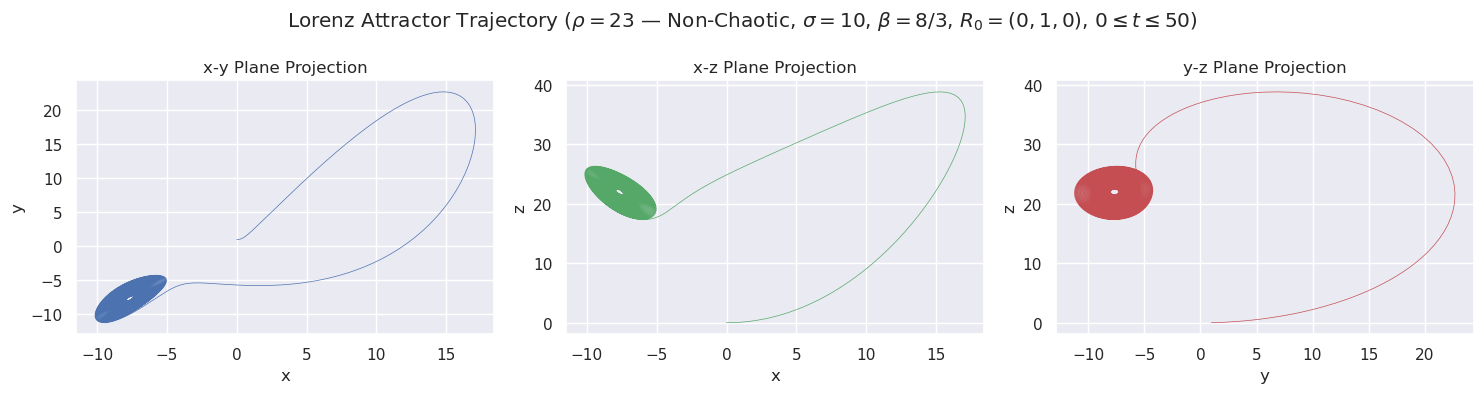

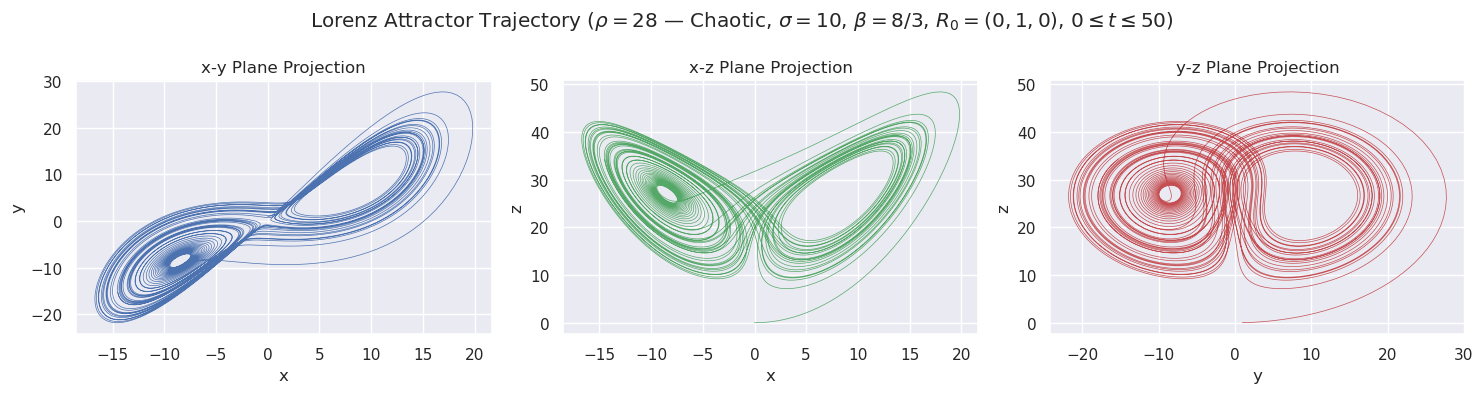

In [3]:
# Parameters
sigma = 10
beta = 8/3

def lorenz(t, R):
    x, y, z = R
    dx = sigma*(y-x)
    dy = rho*x - y - x*z      
    dz = x*y - beta*z

    return np.array([dx, dy, dz])

# Time span (t = 0 to 50), step count, and initial state (x, y, z)
a = 0.0
b = 50.0
n = 10000                         
R0 = np.array([0.0, 1.0, 0.0])    

# Compare non-chaotic (rho < 24.74) and chaotic (rho >= 24.74) regimes
for rho in [23, 28]:
    
    # Integrate ODEs using 4th-order Runge-Kutta and unpack coordinates
    t, R = rk4gen(lorenz, a, b, n, R0)
    x, y, z = R.T          

    # Critical threshold for chaos at sigma = 10, beta = 8/3 is ~24.74
    status = "Chaotic" if rho >= 24.74 else "Non-Chaotic"

    # Plot 2D phase-space projections across the three coordinate planes
    fig, axs = plt.subplots(1, 3, figsize=(15, 4))
    axs[0].plot(x, y, lw=0.5, color="b")
    axs[1].plot(x, z, lw=0.5, color="g")
    axs[2].plot(y, z, lw=0.5, color="r")
    axs[0].set(title="x-y Plane Projection", xlabel="x", ylabel="y")
    axs[1].set(title="x-z Plane Projection", xlabel="x", ylabel="z")
    axs[2].set(title="y-z Plane Projection", xlabel="y", ylabel="z")
    fig.suptitle(fr"Lorenz Attractor Trajectory ($\rho = {rho}$ — {status}, $\sigma = 10$, $\beta = 8/3$, $R_0 = (0, 1, 0)$, $0 \leq t \leq 50$)")
    plt.tight_layout()
    plt.show()

**(b)** Modify your program to produce a plot of $z$ against $x$. You should see a picture of the famous "strange attractor" of the Lorenz equations, a lop-sided butterfly-shaped plot that never repeats itself.

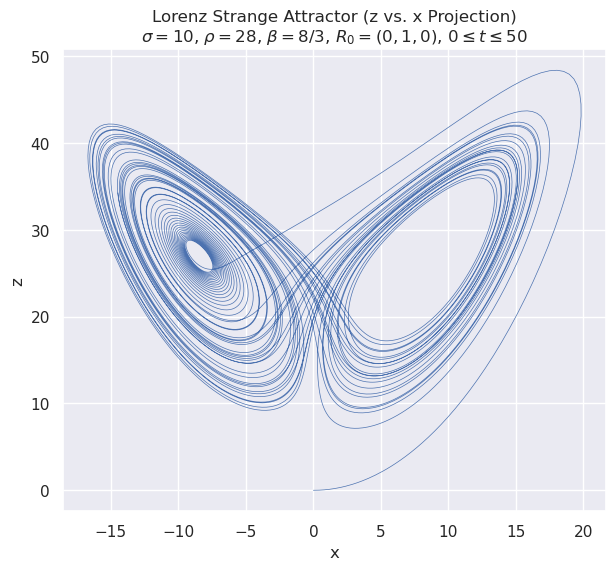

In [5]:
# Plot the x-z phase-space projection to visualize the Lorenz strange attractor
plt.figure(figsize=(7, 6))
plt.plot(x, z, lw=0.5)

# Include parameter values and initial state (R_0) for reference
plt.title("Lorenz Strange Attractor (z vs. x Projection)\n" r"$\sigma = 10$, $\rho = 28$, $\beta = 8/3$, $R_0 = (0, 1, 0)$, $0 \leq t \leq 50$")
plt.xlabel("x")
plt.ylabel("z")
plt.savefig("famous_Lorenz_butterfly_plot.png")
plt.show()

#### Problem 1 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
* The code explores the Lorenz system by simulating how it evolves at two settings (ρ = 23 and ρ = 28) to show the difference between orderly and chaotic behavior. It uses a 4th-order Runge-Kutta solver because that method steps through the equations accurately enough to trace the tiny, sensitive movements that chaos depends on, and it plots the paths in three 2D views since a flat picture of a 3D swirl is easier to read and compare. The final x-z plot of the ρ = 28 run reveals the famous butterfly-shaped "strange attractor," where the path loops endlessly around two centers without ever repeating itself.

### Exercise 2: Second-order ODEs (Harmonic and anharmonic oscillators)

The simple harmonic oscillator arises in many physical problems, in mechanics, electricity and magnetism, and condensed matter physics, among other areas. Consider the standard oscillator equation
$$ \frac{d^2x}{dt^2} = - \omega^2 x $$.

**(a)** Turn this second-order equation into two coupled first-order equations. Then write a program to solve them for the case $\omega = 1$ in the range from $t=0$ to $t= 50$. A second-order equation requires two initial conditions, one on $x$ and one on its derivative. For this problem use $x = 1$ and $\frac{dx}{dt} = 0$ as initial conditions. Have your program
make a graph showing the value of $x$ as a function of time.

$$ \frac{dx}{dt} = y$$
$$ \frac{dy}{dt} = - \omega^2 x $$

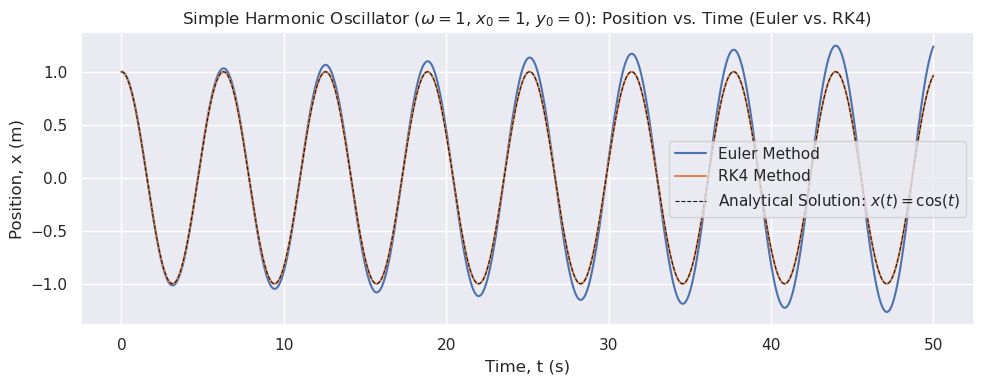

In [6]:
# Angular frequency (rad/s)
omega = 1

# Coupled 1st-order ODEs for simple harmonic motion (x = position, y = velocity)
def sho(t, R):
    x, y = R         
    dx = y
    dy = -omega**2 * x
    return np.array([dx, dy])

# Time interval [0, 50], step count, and initial state [x_0, y_0]
a = 0.0
b = 50.0
n = 5000              
R0 = np.array([1.0, 0.0])

# Solve using 4th-order Runge-Kutta and Euler's method for accuracy comparison
t, R_rk4 = rk4gen(sho, a, b, n, R0)
t, R_euler = eulergen(sho, a, b, n, R0)

# Plot numerical position x(t) (column 0) against the analytical solution
plt.figure(figsize=(10, 4))
plt.plot(t, R_euler[:, 0], label="Euler Method")
plt.plot(t, R_rk4[:, 0], label="RK4 Method")
plt.plot(t, np.cos(t), "k--", lw=0.8, label=r"Analytical Solution: $x(t) = \cos(t)$")
plt.title(r"Simple Harmonic Oscillator ($\omega = 1$, $x_0 = 1$, $y_0 = 0$): Position vs. Time (Euler vs. RK4)")
plt.xlabel("Time, t (s)")
plt.ylabel("Position, x (m)")
plt.legend()
plt.tight_layout()
plt.show()

**(b)** Now increase the amplitude of the oscillations by making the initial value of $x$ bigger --- say $x = 2$ --- and confirm that the period of the oscillations stays roughly the same.

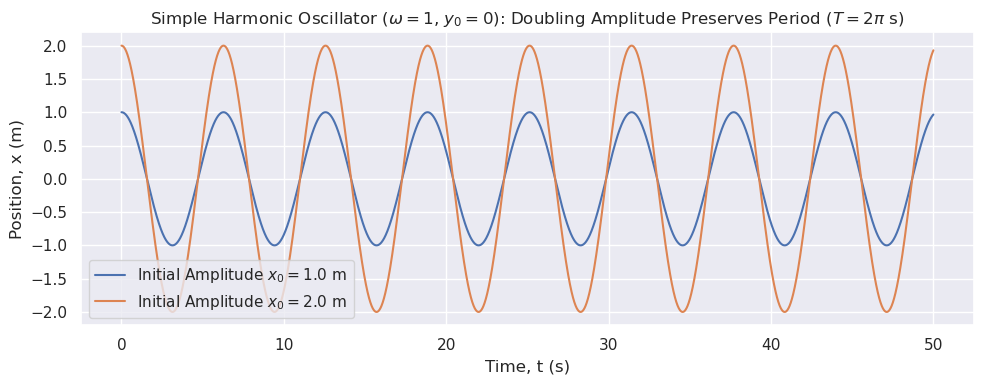

In [7]:
plt.figure(figsize=(10, 4))

# Compare trajectories for initial amplitudes x0 = 1.0 m and 2.0 m (starting from rest)
for x0 in [1.0, 2.0]:
    t, R = rk4gen(sho, a, b, n, np.array([x0, 0.0]))
    
    # Plot position x(t) (column 0 of state array R)
    plt.plot(t, R[:, 0], label=rf"Initial Amplitude $x_0 = {x0}$ m")

# Period T = 2*pi/omega = 2*pi s for omega = 1 rad/s (isochronous property)
plt.title(r"Simple Harmonic Oscillator ($\omega = 1$, $y_0 = 0$): Doubling Amplitude Preserves Period ($T = 2\pi$ s)")
plt.xlabel("Time, t (s)")
plt.ylabel("Position, x (m)")
plt.legend()
plt.tight_layout()
plt.show()

**(c)** Modify your program to solve for the motion of the anharmonic oscillator described by the equation
$$ \frac{d^2 x}{dt} = -\omega^2 x^3.$$

Again take $\omega= 1$ and initial conditions $x = 1$ and $dx/dt = 0$ and make a plot of the motion of the oscillator. Again increase the amplitude. You should observe that the oscillator oscillates faster at higher amplitudes. (You can try lower amplitudes too if you like, which should be slower.)

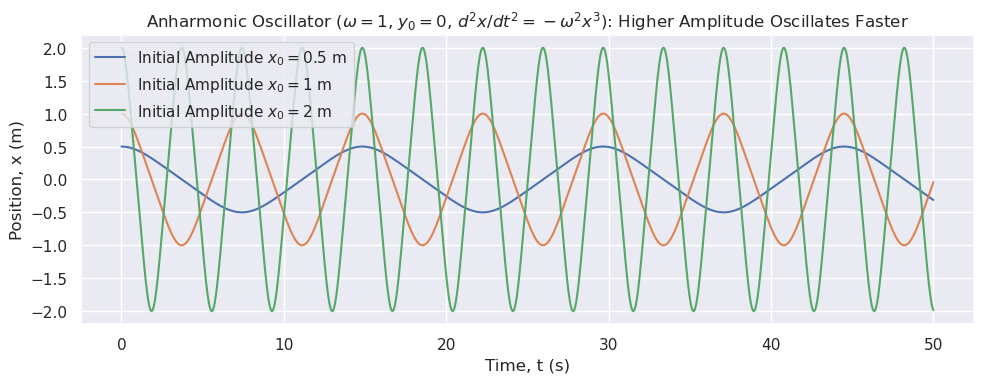

In [8]:
# Coupled 1st-order ODEs for an anharmonic oscillator (x = position, y = velocity)
def anharmonic(t, R):
    x, y = R
    dx = y
    d2x = -omega**2 * x**3    
    return np.array([dx, d2x])

plt.figure(figsize=(10, 4))

# Compare trajectories across low, baseline, and high initial amplitudes (starting from rest)
for x0 in [0.5, 1, 2]:
    t, R = rk4gen(anharmonic, a, b, n, np.array([x0, 0.0]))

    # Plot position x(t) (column 0 of state array R)
    plt.plot(t, R[:, 0], label=rf"Initial Amplitude $x_0 = {x0}$ m")

# Nonlinear restoring force causes oscillation frequency to increase with amplitude
plt.title(r"Anharmonic Oscillator ($\omega = 1$, $y_0 = 0$, $d^2x/dt^2 = -\omega^2 x^3$): Higher Amplitude Oscillates Faster")
plt.xlabel("Time, t (s)")
plt.ylabel("Position, x (m)")
plt.legend()
plt.tight_layout()
plt.show()

**(d)** Modify your program so that instead of plotting $x$ against $t$, it plots $\frac{dx}{dt}$ against $x$, i.e., the "velocity" of the oscillator against its "position." Such a plot is called a *phase space* plot.

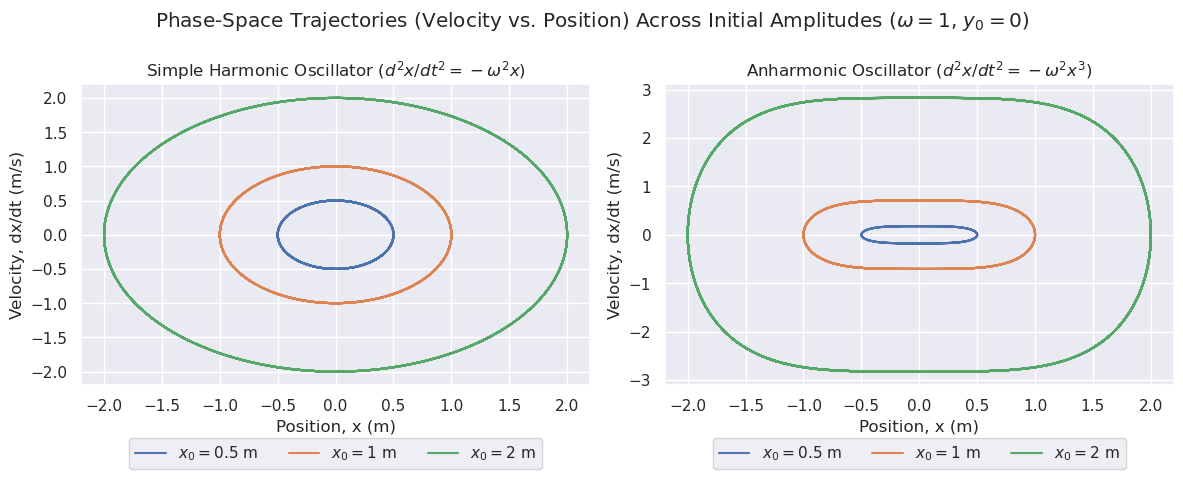

In [9]:
# Create side-by-side subplots to compare harmonic and anharmonic phase portraits
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Sweep over initial amplitudes x0 (starting from rest, y0 = 0)
for x0 in [0.5, 1, 2]:
    
    # Integrate SHO and plot phase trajectory: velocity (col 1) vs. position (col 0)
    t, R = rk4gen(sho, a, b, n, np.array([x0, 0.0]))
    axs[0].plot(R[:, 0], R[:, 1], label=rf"$x_0 = {x0}$ m")

    # Integrate anharmonic oscillator and plot its corresponding phase trajectory
    t, R = rk4gen(anharmonic, a, b, n, np.array([x0, 0.0]))
    axs[1].plot(R[:, 0], R[:, 1], label=rf"$x_0 = {x0}$ m")

# Label subplots with their governing equations and state-space axes
axs[0].set(title=r"Simple Harmonic Oscillator ($d^2x/dt^2 = -\omega^2 x$)", xlabel="Position, x (m)", ylabel="Velocity, dx/dt (m/s)")
axs[1].set(title=r"Anharmonic Oscillator ($d^2x/dt^2 = -\omega^2 x^3$)", xlabel="Position, x (m)", ylabel="Velocity, dx/dt (m/s)")

# Place horizontal legends below each subplot to avoid overlapping the orbits
axs[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
axs[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)

fig.suptitle(r"Phase-Space Trajectories (Velocity vs. Position) Across Initial Amplitudes ($\omega = 1$, $y_0 = 0$)")
plt.tight_layout()   
plt.show()

**(e)** The van der Pol oscillator, which appears in electronic circuits and in laser physics, is described by the equation
$$\frac{d^2x }{dt^2} - \mu(1-x^2)\frac{dx}{dt} + x = 0 $$
Use the same techniques as the one above (i.e. rewrite into 2 1st-order ODEs). Modify your program to solve this equation from $t=0$ to $t=20$ and hence make a phase space plot for the van der Pol oscillator with $\omega=1$, $\mu = 1$, and initial conditions $x = 1$ and $dx/dt = 0$. Try it also for $\mu=2$ and $\mu=4$ (still with $\omega = 1$). Make sure you use a small enough value of the time interval $h$ to get a smooth, accurate phase space plot.

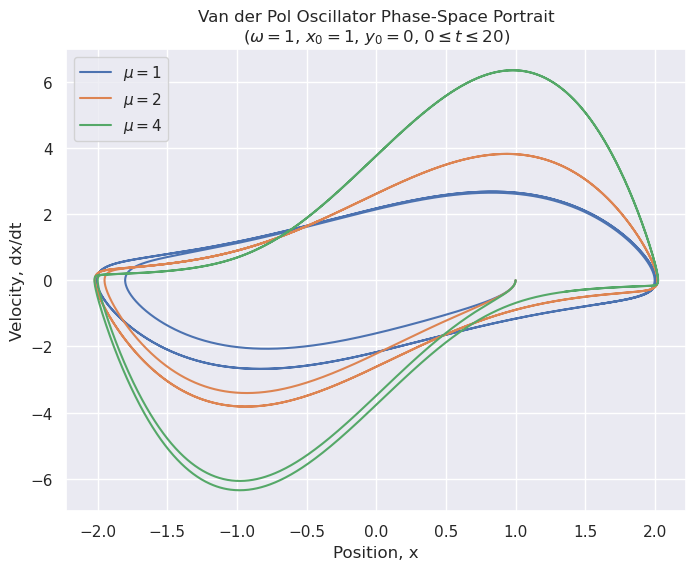

In [10]:
# Coupled 1st-order ODEs for the van der Pol oscillator (x = position, y = velocity)
def vanderpol(t, R):
    x, y = R
    dx = y
    d2x = mu*(1 - x**2)*y - x      
    return np.array([dx, d2x])

# Time interval [0, 20], fine step count (h = 0.001) for stiff relaxation oscillations, and initial state [x_0, y_0]
a, b, n = 0.0, 20.0, 20000         
R0 = np.array([1.0, 0.0])

plt.figure(figsize=(8, 6))

# Sweep over nonlinear damping strengths (mu) to show limit-cycle distortion
for mu in [1, 2, 4 ]:
    t, R = rk4gen(vanderpol, a, b, n, R0)
    
    # Plot phase portrait: velocity dx/dt (col 1) vs. position x (col 0)
    plt.plot(R[:, 0], R[:, 1], label=fr"$\mu = {mu}$")

plt.title("Van der Pol Oscillator Phase-Space Portrait\n"
          r"($\omega = 1$, $x_0 = 1$, $y_0 = 0$, $0 \leq t \leq 20$)")
plt.xlabel("Position, x")
plt.ylabel("Velocity, dx/dt")
plt.legend()
plt.savefig("vanderpol.png")
plt.show()

#### Problem 2 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
* The code studies three kinds of oscillators (a simple spring, an anharmonic one, and the van der Pol system) by turning each second-order equation into two simple first-order ones (position and velocity) so a single step-by-step solver can handle them all. It uses the accurate Runge-Kutta method and checks it against the Euler method and the exact cosine answer, because small step errors would otherwise make the motion drift or fake energy gains, while the fine step size for van der Pol keeps its sharp, sudden swings from being missed. By plotting position over time and velocity against position, it makes the key ideas visible: a normal spring keeps the same rhythm no matter how far you pull it, the anharmonic one speeds up with bigger swings, and van der Pol settles into a steady loop that gets more distorted as its nonlinear damping strength grows.

---
## Section 3: Notes

In [ ]:
# forward Euler's method

def euler(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        y += h*f(x, y)
    return xs, ys

In [ ]:
# 2nd order Runge-Kutta method

def rk2(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k1 = h*f(x, y)
        k2 = h*f(x+0.5*h, y+0.5*k1)
        y += k2
    return xs, ys

In [ ]:
# 4th order Runge-Kutta method (1 equation only, use the code below for simultaneous eqns)

def rk4(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k0 = h*f(x, y)
        k1 = h*f(x+h/2, y+k0/2)
        k2 = h*f(x+h/2, y+k1/2)
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

In [ ]:
# execution
a, b, n, yinit = 0.05, 0.49, 5, 19.53

def f(x,y):
    ...

xs, ys = euler(f,a,b,n,yinit); print(ys)
plt.plot(xs,ys, label='Euler')
xs, ys = rk2(f,a,b,n,yinit); print(ys)
plt.plot(xs,ys, label='RK2')
xs, ys = rk4(f,a,b,n,yinit); print(ys)
plt.plot(xs,ys, label='RK4')
plt.legend()
plt.show()

#### Solving IVP problem of 2 simultaneous ODEs

In [ ]:
def fs(x,yvals):
    y0, y1 = yvals
    f0 = y1
    f1 = - (30/(1-x**2))*y0 + ((2*x)/(1-x**2))*y1
    return np.array([f0, f1])

def rk4gen(fs,a,b,n,yinits):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j,x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals)
        k1 = h*fs(x+h/2, yvals+k0/2)
        k2 = h*fs(x+h/2, yvals+k1/2)
        k3 = h*fs(x+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

a, b, n = 0.05, 0.49, 12
yinits = np.array([0.0926587109375, 1.80962109375])
xs, ys = rk4gen(fs,a,b,n,yinits)
print(ys)

In [ ]:
def eulergen(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit)))
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        y += h*f(x, y)
    return xs, ys

### Plotting

In [ ]:
# SAMPLE DATA ONLY
t = np.linspace(0, 10, 1000)
x = np.sin(t)
y = np.cos(t)
z = np.cos(2*t)

x1 = np.sin(t + 1)
y1 = np.cos(2*t + 2)
z1 = np.cos(3*t)

# See: https://stackoverflow.com/questions/10388462/matplotlib-different-size-subplots
fig, axs = plt.subplots(3, 2, figsize=(10, 6), gridspec_kw={'width_ratios': [3, 1]})

# Time series
axs[0, 0].plot(t, x, label="Param 1")
axs[0, 0].plot(t, x1, label="Param 2")
axs[0, 0].legend()
axs[0, 0].set_ylabel("X(t)")

axs[1, 0].plot(t, y)
axs[1, 0].plot(t, y1)
axs[1, 0].set_ylabel("Y(t)")

axs[2, 0].plot(t, z)
axs[2, 0].plot(t, z1)
axs[2, 0].set_ylabel("Z(t)")

# add xlabel to all time series
for ax in axs[:, 0]:
    ax.set_xlabel("time t")

# Phase plot
axs[0, 1].plot(x, y)
axs[0, 1].set(title="X-Y Projection", xlabel="X", ylabel="Y")

axs[1, 1].plot(y, z)
axs[1, 1].set(title="Y-Z Projection", xlabel="Y", ylabel="Z")

axs[2, 1].plot(x, z)
axs[2, 1].set(title="X-Z Projection", xlabel="X", ylabel="Z")

fig.tight_layout()